# pipeline
1. load a complete sequence
2. split it chronological into train, val, and test sets
3. fit scaling using training data
4. standardize train, validation, and test
5. create windows separately for each split
6. train/eval with those windows

In [118]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [119]:
# %pip install scikit-learn, torch

import os
import random
import numpy as np
np.set_printoptions(threshold=np.inf)
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from sklearn.metrics import precision_recall_fscore_support, average_precision_score, roc_auc_score

import pandas as pd
pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)


In [120]:
data_path = '/content/drive/MyDrive/CMPE257-data'
SMAP_path = data_path + "/SMAP"
SVDB_path = data_path + "/SVDB"

SEED=42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# batch_size = 32
# num_workers = 2
window_size = 20
num_epochs = 30

(8209, 25) (8209,) anomaly rate: 0.13655743695943476


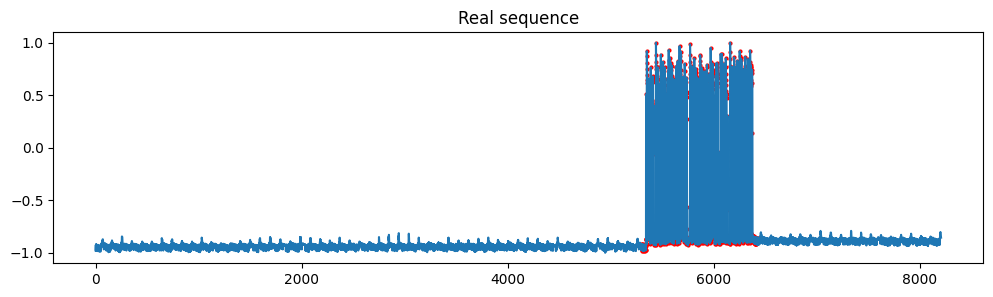

In [121]:
# example of complete sequence from SMAP
d_path = '/content/drive/MyDrive/CMPE257-data/SMAP/144_SMAP_id_1_Sensor_tr_2052_1st_5300.csv'
df1 = pd.read_csv(d_path)

v = df1.copy().drop(columns='Label')
y = df1.copy()['Label']

mask = y == 1

print(v.shape, y.shape, 'anomaly rate:', y.mean())
plt.figure(figsize=(12,3))
plt.plot(v.index, v.iloc[:,0])
plt.scatter(v.index[mask], v.loc[mask].iloc[:,0],s=4,c='red')
plt.title('Real sequence')
plt.show()



(6000, 2) (6000,) anomaly rate: 0.02666666666666667


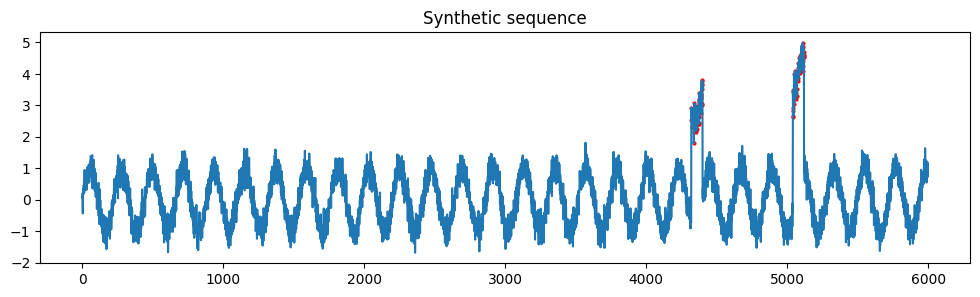

In [122]:
# exmaple of synthetic sequence
# create fake time-series data with 6000 time-steps and 2 features to test that chronological split and other functions work before testing with the real data
# each feature/column has its own wave pattern

def make_synthetic_sequence(n=6000, d=2):
  rng = np.random.default_rng(SEED) # rng noise generator
  t = np.arange(n) # time indices
  values = np.column_stack([np.sin(t/35), np.cos(t/60)]) + 0.25*rng.normal(size=(n,d))
  labels = np.zeros(n)

  # inserting anomalies
  starts = [int(.72*n), int(.84*n)] # starting row of an anomaly
  for start in starts:
    end = min(start+80, n)
    values[start:end] += 3.5
    labels[start:end] = 1

  return values, labels

values, labels = make_synthetic_sequence(n=6000, d=2)
print(values.shape, labels.shape, 'anomaly rate:', labels.mean())
plt.figure(figsize=(12,3)); plt.plot(values[:,0])
plt.scatter(np.where(labels==1)[0],values[labels==1,0],s=4,c='red')
plt.title('Synthetic sequence')
plt.show()


In [123]:
def chronological_split(v, y, train_percent=.6, val_percent=.2):
  n = len(v)
  i = int(n * train_percent) # pointer for end of train
  j = int(n * (val_percent + train_percent)) # pointer for end of val

  train = (v[:i], y[:i])
  val = (v[i:j], y[i:j])
  test = (v[j:], y[j:])

  return train, val, test

def standardize_fit(v):
  mean = v.mean(axis=0, keepdims=True)
  std = v.std(axis=0, keepdims=True)
  std = np.where(std < 1e-6, 1., std) # for preventing division by 0 or producing large numbers

  return mean, std

def standardize(v, mean, std):
  return (v - mean) / std

def make_windows(v, y, w=window_size):
  context, x, labels, idx = [], [], [], []

  for t in range(w, len(v)):
    context.append(v[t-w:t])
    x.append(v[t])
    labels.append(y[t])
    idx.append(t)

  context = np.asarray(context, dtype=np.float32)
  x = np.asarray(x, dtype=np.float32)
  labels = np.asarray(labels, dtype=np.int64)
  idx = np.asarray(idx, dtype=np.int64)

  return x, context, labels, idx



In [124]:
(train_v, train_y), (val_v, val_y), (test_v, test_y) = chronological_split(values, labels)
print(train_v.shape, train_y.shape)
print(val_v.shape, val_y.shape)
print(test_v.shape, test_y.shape)

(3600, 2) (3600,)
(1200, 2) (1200,)
(1200, 2) (1200,)


In [125]:
mean, std = standardize_fit(train_v)
print(mean, std)

[[ 0.01717408 -0.00692324]] [[0.75351692 0.75215255]]


In [126]:
print('Before standardizing: ', train_v.mean())

train_v = standardize(train_v, mean, std)
print('After standardizing: ', train_v.mean())
'''
plt.figure(figsize=(12,3))
plt.plot(train_v[:,0])
plt.title('Synthetic sequence')
plt.show()
'''

Before standardizing:  0.005125422759598206
After standardizing:  -4.342205607422835e-17


"\nplt.figure(figsize=(12,3))\nplt.plot(train_v[:,0])\nplt.title('Synthetic sequence')\nplt.show()\n"

In [127]:
train_x, train_c, train_labels, _ = make_windows(train_v, train_y, window_size)
val_x, val_c, val_labels, _ = make_windows(val_v, val_y, window_size)
test_x, test_c, test_labels, _ = make_windows(test_v, test_y, window_size)

In [128]:
# the baseline CNF
# the conditional affline coupling (flips the masks and computes scale (s|c) and translation (t|c) factors for each layer)
# the condtional RealNVP (forward pass through affline coupling layers then gets the gaussian distribution (z) then solve for likelihood of pz(z|c), then inverse pass solve for px(x|c) )

class ConditionalAffineCouplingLayer(nn.Module):
  def __init__(self, dim, context_dim, mask, hidden=128):
    super().__init__()

    self.register_buffer(
        'mask',
        torch.tensor(mask)
    )

    self.net = nn.Sequential(
        nn.Linear(in_features = dim + context_dim, out_features = hidden),
        nn.ReLU(),
        nn.Linear(in_feauures=hidden, out_feautures=hidden),
        nn.ReLU(),
        nn.Linear(in_features=hidden, out_features=dim*2) # produces scale and translation, which in total is double the amount of the input
    )

  def forward(self, x, c):
    z_a = x * self.mask # unchanged features

    net_input = torch.cat([z_a, c], dim=-1)
    s, t = self.net(net_input).chunk(2, dim=-1)

    s = 2.0 * torch.tanh(s / 2.0) * (1.0 - self.mask)

    z_b = (1.0 - self.mask) * (x * torch.exp(s) + t) # transformed features

    z = z_a + z_b

    log_det = s.sum(dim=-1)

    return z, log_det

# pass the window into the coupling layer, calculate the likelihood Pz(z)
class ConditionalRealNVP(nn.Module):
  def __init__(self, dim, w, hidden=128, context_dim=128, layer=6):
    super().__init__()

    # flatten context window and turn it into context representation
    self.context_encoder = nn.Sequential(
        nn.Linear(w * dim, hidden),
        nn.ReLU(),
        nn.Linear(hidden, context_dim),
        nn.ReLU()
    )

    mask = [ 1.0 if i % 2 == 0 else 0.0 for i in range(dim)]

    self.layers = nn.ModuleList([
        ConditionalAffineCouplingLayer(
            dim,
            context_dim,
            mask,
            hidden
        )
        for i in range(layers)
    ])

  def encode_context(self, context_window):
    # (batch_size, window_size, dim) -> (batch_size, context_dim)

    flattened_context = context_window.flatten(start_dim=1)
    return self.context_encoder(flattened_context)

  def log_prob(self, x, context_window):
    # calculate log p(x|c)
    context_embedding = self.encode_context(context_window)
    total_log_det = torch.zeros(
        x.shape[0],
        device=x.device
    )

    z = x
    for layer in self.layers:
      z, log_det = layer(z, context_embedding)
      total_log_det += log_det

    # evaluzate final z under a standard gaussian distribution
    standard_normal_log_prob = -0.5 * (z.pow(2) + np.log(2.0 * np.pi)).sum(dim=-1)

    # log p(x|c) = log p(z) + log|det(dz/dx)|
    return standard_normal_log_prob + total_log_det

  def nll(x, context_window):
    # return avg negative log-likelihood for a batch

    log_prob = self.log_prob(x, context_window)

    return -log_prob.mean()


In [129]:
# dataloader
def make_dataloader(X, context_windows, batch_size=256, shuffle=True):
  # group context windows with the training observations into batches
  target_tensor = torch.tensor(
      X,
      dtype=torch.float32
  )

  context_tensor = torch.tensor(
      context_windows,
      dtype=torch.float32
  )

  dataset = TensorDataset(
      target_tensor,
      context_tensor
  )

  return DataLoader(
      dataset,
      batch_size=batch_size,
      shuffle=shuffle
  )

In [136]:
# set up model

num_features = train_x.shape[1]

model = ConditionalRealNVP(
    dim=num_features,
    w=window_size,
    hidden_dim=128,
    context_dim=128,
    layers=6
).to(DEVICE)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)

train_loader = make_dataloader(
    train_x,
    train_c,
    batch_size=256,
    shuffle=True
)

val_loader = make_dataloader(
    val_x,
    val_c,
    batch_size=256,
    shuffle=False
)

2


In [ ]:
# need to establish a nll threshold to detect anomalies
# need to create a nll scoring function + the main training eval loop functions,
# the dataloader does not fetch from SMAP/SVDB at the moment

# when we build the second model
# need to change datalaoder and add the latent dynamics rule

# would like to add plot visuals